# 01 - Building segmentation (SAM3) + depth (Depth Anything V2)
Objective: Assess feasibility of converting skyline images to music. 

For each skyline in `data/`:
1. Depth Anything V2 -> relative depth map (`outputs/depth/`)
2. SAM3 with the text prompt `"building"` -> instance masks (`outputs/masks/`)
3. Summary figure, one row per city (`outputs/fig_seg_depth.png`)


In [1]:
%pip install -q transformers accelerate

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os, gc
from pathlib import Path
import numpy as np, torch
import matplotlib.pyplot as plt
from PIL import Image


def setup_env():
    """Return the project root. Colab: Drive folder (SKYLINE_ROOT overrides); local: repo root."""
    if os.environ.get("SKYLINE_ROOT"):
        return Path(os.environ["SKYLINE_ROOT"])
    try:
        from google.colab import drive, userdata  # only importable on Colab
    except ImportError:
        cwd = Path.cwd()
        return cwd.parent if cwd.name == "notebooks" else cwd
    drive.mount("/content/drive")
    try:  # gated models (SAM3): add HF_TOKEN under Colab Secrets
        os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    except Exception:
        print("No HF_TOKEN in Colab Secrets; gated models will fail to load.")
    return Path("/content/drive/MyDrive/skyline2music")


ROOT = setup_env()
DATA, OUT = ROOT / "data", ROOT / "outputs"
os.environ.setdefault("HF_HOME", str(ROOT / "hf_cache"))
for d in ("depth", "masks"):
    (OUT / d).mkdir(parents=True, exist_ok=True)

MAX_SIDE = 1536  # downscale long side
device = "cuda" if torch.cuda.is_available() else "cpu"


def load(path):
    im = Image.open(path).convert("RGB")
    s = MAX_SIDE / max(im.size)
    return (
        im.resize((round(im.width * s), round(im.height * s)), Image.LANCZOS)
        if s < 1
        else im
    )


paths = sorted(
    p for p in DATA.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)
images = {p.stem: load(p) for p in paths}
for k, v in images.items():
    print(k, v.size)
print("ROOT:", ROOT, "| device:", device)

chicago (1536, 1023)
seattle (1536, 584)
singapore (1440, 600)
taipei (776, 360)
NVIDIA GeForce RTX 3080 Ti Laptop GPU


## Depth Anything V2
Outputs *relative inverse depth* (larger = closer), not metric depth. Haze at distance is the expected failure mode.

In [ ]:
from transformers import pipeline

depth_pipe = pipeline(
    "depth-estimation",
    model="depth-anything/Depth-Anything-V2-Large-hf",
    device=device,
    dtype=torch.float16,
)
depths = {}
for name, im in images.items():
    d = depth_pipe(im)["predicted_depth"].squeeze().float().cpu().numpy()
    d = np.array(Image.fromarray(d).resize(im.size, Image.BILINEAR))
    d = (d - d.min()) / (d.max() - d.min() + 1e-8)
    depths[name] = d
    np.save(OUT / "depth" / f"{name}.npy", d)
    plt.imsave(OUT / "depth" / f"{name}.png", d, cmap="magma")

del depth_pipe
gc.collect()
torch.cuda.empty_cache()
print("saved depth for", list(depths))

Loading weights:   0%|          | 0/503 [00:00<?, ?it/s]

saved depth for ['chicago', 'seattle', 'singapore', 'taipei']


## SAM3 with the "building" prompt
`threshold` is the instance score cutoff and `mask_threshold` binarizes each mask.

In [ ]:
from transformers import Sam3Processor, Sam3Model

try:
    processor = Sam3Processor.from_pretrained("facebook/sam3")
    sam = Sam3Model.from_pretrained("facebook/sam3").to(device).eval()
except Exception as e:
    raise RuntimeError(
        "Could not load facebook/sam3. Request access at "
        "https://huggingface.co/facebook/sam3 and check HF_TOKEN."
    ) from e

PROMPT, SCORE_THR = "building", 0.5
seg = {}
for name, im in images.items():
    inputs = processor(images=im, text=PROMPT, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = sam(**inputs)
    res = processor.post_process_instance_segmentation(
        outputs,
        threshold=SCORE_THR,
        mask_threshold=0.5,
        target_sizes=inputs.get("original_sizes").tolist(),
    )[0]
    masks = res["masks"].cpu().numpy().astype(bool)
    seg[name] = dict(
        masks=masks,
        boxes=res["boxes"].cpu().numpy(),
        scores=res["scores"].cpu().numpy(),
    )
    np.savez_compressed(OUT / "masks" / f"{name}.npz", **seg[name])
    print(f"{name}: {len(masks)} building instances")

[transformers] `memory_attention_rope_theta` is deprecated and will be removed in v5.0. Use `rope_parameters['rope_theta']` instead.


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1468 [00:00<?, ?it/s]

chicago: 34 building instances


seattle: 55 building instances


singapore: 42 building instances


taipei: 37 building instances


In [ ]:
def overlay(im, masks, seed=0):
    rng = np.random.default_rng(seed)
    out = np.asarray(im).astype(float)
    for m in masks:
        out[m] = 0.45 * out[m] + 0.55 * rng.integers(40, 255, 3)
    return out.astype(np.uint8)


for name, im in images.items():
    Image.fromarray(overlay(im, seg[name]["masks"])).save(
        OUT / "masks" / f"{name}_overlay.png"
    )

## Summary

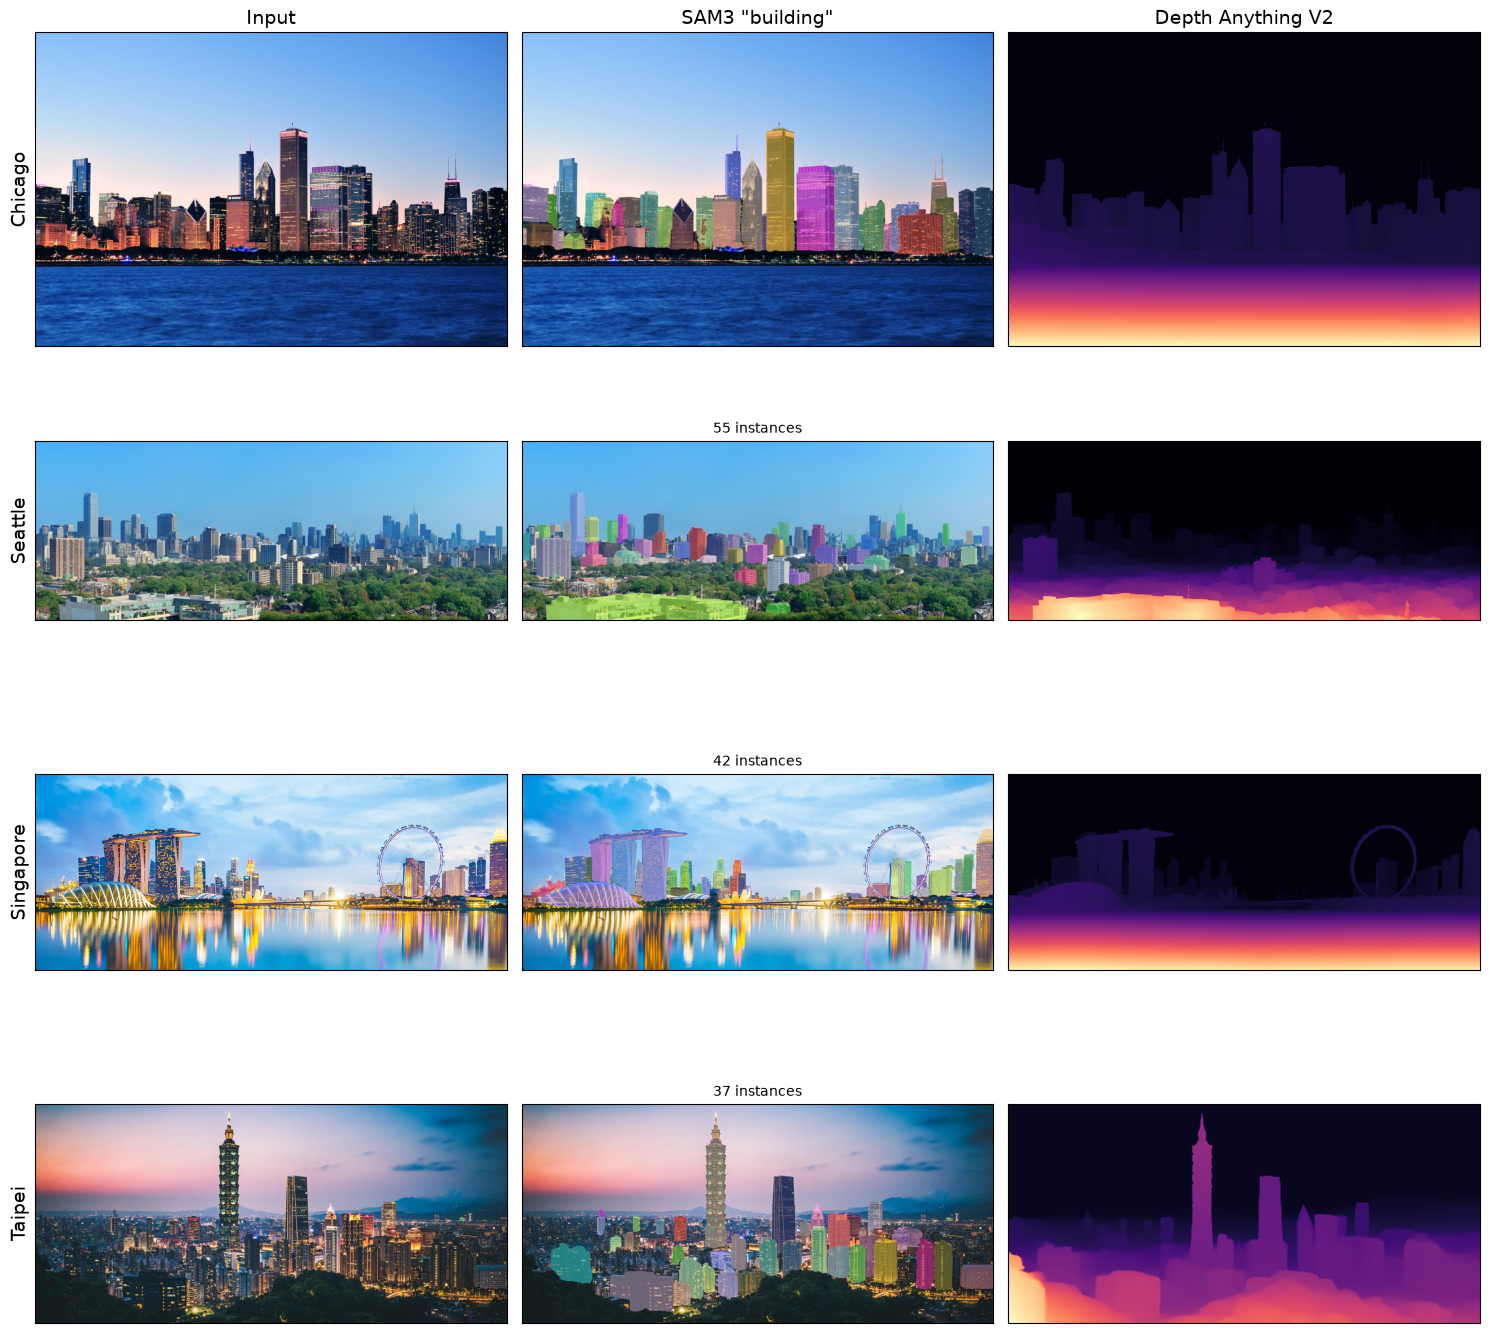

In [ ]:
names = list(images)
fig, axes = plt.subplots(len(names), 3, figsize=(15, 3.6 * len(names)))
for r, name in enumerate(names):
    axes[r, 0].imshow(images[name])
    axes[r, 0].set_ylabel(name.title(), fontsize=14)
    axes[r, 1].imshow(overlay(images[name], seg[name]["masks"]))
    axes[r, 1].set_title(f"{len(seg[name]['masks'])} instances", fontsize=10)
    axes[r, 2].imshow(depths[name], cmap="magma")
    for a in axes[r]:
        a.set_xticks([])
        a.set_yticks([])
for a, t in zip(axes[0], ["Input", 'SAM3 "building"', "Depth Anything V2"]):
    a.set_title(t, fontsize=14)
plt.tight_layout()
fig.savefig(OUT / "fig_seg_depth.png", dpi=150)
plt.show()